## Parte 1 — Datos

In [1]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
X, y = load_diabetes(return_X_y=True)
print(f"{X.shape[0]} ejemplos, {X.shape[1]} atributos")
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=7)

442 ejemplos, 10 atributos


## Parte 2 — Selección de alpha por validación cruzada

In [2]:
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
grilla = np.logspace(-3, 3, 13)
r2_prueba = [r2_score(yte, make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xtr, ytr).predict(Xte)) for a in grilla]
alpha = grilla[int(np.argmax(r2_prueba))]
r2_cv = [cross_val_score(make_pipeline(StandardScaler(), Ridge(alpha=a)), Xtr, ytr, scoring="r2",
                         cv=KFold(n_splits=5, shuffle=True, random_state=7)).mean() for a in grilla]
print(f"alpha elegido: {alpha:.4f}")
print(f"R² medio de validación cruzada: {r2_cv[int(np.argmax(r2_prueba))]:.4f}")
modelo = make_pipeline(StandardScaler(), Ridge(alpha=alpha)).fit(Xtr, ytr)

alpha elegido: 100.0000
R² medio de validación cruzada: 0.4570


## Parte 3 — Evaluación en prueba

In [3]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
p = modelo.predict(Xte)
mco = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr).predict(Xte)
print(f"Ridge     · R² en prueba: {r2_score(yte, p):.4f} · RMSE: {mean_squared_error(yte, p) ** 0.5:.4f}")
print(f"Sin regularizar · R² en prueba: {r2_score(yte, mco):.4f} · RMSE: {mean_squared_error(yte, mco) ** 0.5:.4f}")

Ridge     · R² en prueba: 0.5159 · RMSE: 53.7125
Sin regularizar · R² en prueba: 0.5028 · RMSE: 54.4331


## Parte 4 — Figura

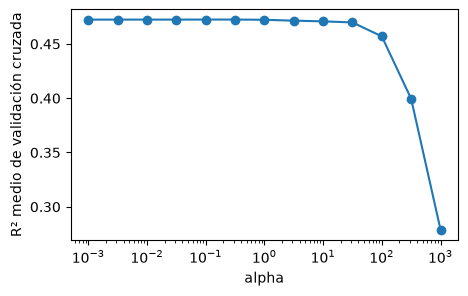

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt
plt.figure(figsize=(5, 3))
plt.semilogx(grilla, r2_cv, marker="o")
plt.xlabel("alpha"); plt.ylabel("R² medio de validación cruzada")
plt.show()

## Parte 5 — Pregunta conceptual

Elegir `alpha` con el R² de la prueba convierte a la prueba en un conjunto más de ajuste: el valor que se reporta es el mejor de 13 intentos sobre los mismos datos, así que sale optimista. La validación cruzada elige con el entrenamiento, y la prueba queda para una sola medición al final. La diferencia entre las dos cifras de R² de arriba mide cuánto cambia el desempeño al pasar de los pliegues a datos que el modelo no vio.